# Comparaci?n de Qwen2.5-7B, Qwen2.5-1.5B y Qwen3.5-9B: BASE vs LoRA/QLoRA

Notebook independiente para comparar variantes BASE, ajustadas con prompts zero/one/few y el adaptador GRPO de Qwen2.5-1.5B. Conserva los experimentos existentes y a?ade `Qwen3.5-9B` mediante QLoRA.

- Reutiliza las predicciones y cach?s existentes cuando est?n completas.
- Si falta un adaptador QLoRA de Qwen3.5-9B, la celda de ejecuci?n lanza expl?citamente su script de entrenamiento.
- Qwen3.5-9B se carga siempre con 4-bit NF4 y double quantization, tanto BASE como QLoRA.
- Mantiene el mismo split 80/20, contextos RAG locales y m?tricas EM, F1, BLEU-1 y ROUGE-1.
- Los prompts de Qwen3.5-9B se leen desde el prompt exacto guardado por el entrenamiento cuando est? disponible.
- Las salidas se incorporan a las tablas y gr?ficas comparativas sin modificar los resultados anteriores.
- `1.5B_GRPO` reutiliza `models/grpo_adapter` y genera su cach? en un CSV independiente cuando falta.


In [1]:
from pathlib import Path
import sys, os, json, time, gc, random, subprocess
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (PROJECT_ROOT / "src" / "preprocess" / "preprocess.py").exists():
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "preprocess" / "preprocess.py").exists():
    raise FileNotFoundError("Abre Jupyter desde la raíz de Practica_PLN_II.")
sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42
MAX_LENGTH = 384
MAX_NEW_TOKENS = 32
PRINT_EVERY = 10
WARMUP_QUESTIONS = 1
LIMIT_TEST = None  # 5 para una prueba rápida; None para todo el test

MODEL_IDS = {
    "7B": "Qwen/Qwen2.5-7B-Instruct",
    "1.5B": "Qwen/Qwen2.5-1.5B-Instruct",
    "9B": "Qwen/Qwen3.5-9B",
}
ADAPTERS = {
    "7B_FT_zero": PROJECT_ROOT / "models" / "prompt_training_controlled" / "qwen_lora_controlled_zero",
    "7B_FT_one": PROJECT_ROOT / "models" / "prompt_training_controlled" / "qwen_lora_controlled_one",
    "7B_FT_few": PROJECT_ROOT / "models" / "prompt_training_controlled" / "qwen_lora_controlled_few",
    "1.5B_FT_zero": PROJECT_ROOT / "models" / "prompt_training_controlled_qwen15" / "qwen15_lora_controlled_zero",
    "1.5B_FT_one": PROJECT_ROOT / "models" / "prompt_training_controlled_qwen15" / "qwen15_lora_controlled_one",
    "1.5B_FT_few": PROJECT_ROOT / "models" / "prompt_training_controlled_qwen15" / "qwen15_lora_controlled_few",
    "1.5B_GRPO": PROJECT_ROOT / "models" / "grpo_adapter",
    "9B_FT_zero": PROJECT_ROOT / "models" / "prompt_training_controlled_qwen35_9b" / "qwen35_9b_lora_controlled_zero",
    "9B_FT_one": PROJECT_ROOT / "models" / "prompt_training_controlled_qwen35_9b" / "qwen35_9b_lora_controlled_one",
    "9B_FT_few": PROJECT_ROOT / "models" / "prompt_training_controlled_qwen35_9b" / "qwen35_9b_lora_controlled_few",
}
PROMPT_FILES = {"zero": "controlled_zero.md", "one": "controlled_one.md", "few": "controlled_few.md"}
INDEX_PATH = PROJECT_ROOT / "models" / "context_embeddings.pt"
QUESTIONS_PATH = PROJECT_ROOT / "data" / "questions_train.json"
CONTEXTS_PATH = PROJECT_ROOT / "data" / "contexts.json"
PROMPTS_DIR = PROJECT_ROOT / "prompts"
OUTPUT_DIR = PROJECT_ROOT / "results" / "rag_prompt_comparison_6models"
QWEN35_RESULTS_ROOT = PROJECT_ROOT / "results" / "prompt_training_controlled_qwen35_9b"
QWEN35_TRAIN_SCRIPT = PROJECT_ROOT / "scripts" / "experiments" / "train_qwen35_9b_qlora.py"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else (
    torch.float16 if DEVICE.type == "cuda" else torch.float32
)
print("Raíz:", PROJECT_ROOT, "| dispositivo:", DEVICE, "| dtype:", DTYPE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Resultados nuevos:", OUTPUT_DIR)
for p in [QUESTIONS_PATH, CONTEXTS_PATH, INDEX_PATH]:
    print(("OK" if p.exists() else "FALTA"), p)


Raíz: C:\Users\chech\Practica_PLN_II | dispositivo: cuda | dtype: torch.bfloat16
GPU: NVIDIA GeForce RTX 5060 Ti
Resultados nuevos: C:\Users\chech\Practica_PLN_II\results\rag_prompt_comparison_6models
OK C:\Users\chech\Practica_PLN_II\data\questions_train.json
OK C:\Users\chech\Practica_PLN_II\data\contexts.json
OK C:\Users\chech\Practica_PLN_II\models\context_embeddings.pt


## 2. Datos, split y contextos RAG
Se mantiene el mismo split y se recupera el contexto una sola vez para compartirlo entre las variantes (incluyendo Qwen3.5-9B y `1.5B_GRPO`).


In [2]:
from src.preprocess.preprocess import prepare_dataset
from src.evaluate import exact_match_score, f1_score, bleu_score, rouge_score
from src.retrieval.context_retriever import ContextRetriever

for path in (QUESTIONS_PATH, CONTEXTS_PATH, INDEX_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Falta archivo requerido: {path}")

dataset = prepare_dataset(str(QUESTIONS_PATH), str(CONTEXTS_PATH))
train_data, test_data = train_test_split(dataset, test_size=0.2, random_state=SEED)
train_data, test_data = [dict(x) for x in train_data], [dict(x) for x in test_data]
if LIMIT_TEST is not None:
    test_data = test_data[:LIMIT_TEST]
print(f"Total={len(dataset)} | train={len(train_data)} | test={len(test_data)}")

retriever = ContextRetriever(str(INDEX_PATH), device=DEVICE)
retrieved_test = []
for i, item in enumerate(test_data):
    r = retriever.retrieve(item["question"])
    retrieved_test.append({
        **item,
        "context": r.get("context", "") or "",
        "retrieved_context_id": r.get("context_id", "none"),
        "retrieval_score": float(r.get("score", 0.0)),
    })
    if (i + 1) % PRINT_EVERY == 0 or i + 1 == len(test_data):
        print(f"[RAG] {i+1}/{len(test_data)}", flush=True)

# Construir ejemplos de demostración únicamente a partir de train.
retrieved_train = []
for i, item in enumerate(train_data):
    r = retriever.retrieve(item["question"])
    retrieved_train.append({**item, "context": r.get("context", "") or ""})
    if (i + 1) % 50 == 0 or i + 1 == len(train_data):
        print(f"[Train demos] {i+1}/{len(train_data)}", flush=True)

answerable = [x for x in retrieved_train if x.get("has_answer") and x.get("answer") and x.get("context")]
unanswerable = [x for x in retrieved_train if not x.get("has_answer")]
if len(answerable) < 3:
    raise ValueError("No hay suficientes ejemplos respondibles para crear prompts.")
short = min(answerable, key=lambda x: len(x["answer"].split()))
medium_candidates = [x for x in answerable if x is not short and 1 <= len(x["answer"].split()) <= 5]
medium = medium_candidates[0] if medium_candidates else next(x for x in answerable if x is not short)
long_candidates = [x for x in answerable if x is not short and x is not medium]
examples = [short, medium, max(long_candidates, key=lambda x: len(x["answer"].split()))]
if unanswerable:
    examples.append(unanswerable[0])
examples = [{"context": x.get("context",""), "question": x["question"], "answer": x.get("answer") or ""} for x in examples[:4]]

def make_prompt(strategy):
    path = PROMPTS_DIR / PROMPT_FILES[strategy]
    if not path.exists():
        raise FileNotFoundError(f"No encuentro {path}. Comprueba que existen los prompts controlados.")
    template = path.read_text(encoding="utf-8").strip()
    if strategy == "zero":
        return template
    if strategy == "one":
        e = examples[0]
        return template.format(example_context=e["context"], example_question=e["question"], example_answer=e["answer"])
    values = {}
    for i, e in enumerate(examples[:4], start=1):
        values[f"example_{i}_context"] = e["context"]
        values[f"example_{i}_question"] = e["question"]
        values[f"example_{i}_answer"] = e["answer"]
    return template.format(**values)

SYSTEM_PROMPTS = {s: make_prompt(s) for s in ("zero", "one", "few")}
print("Longitudes prompts:", {k: len(v) for k,v in SYSTEM_PROMPTS.items()})


Total=350 | train=280 | test=70


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[RAG] 10/70
[RAG] 20/70
[RAG] 30/70
[RAG] 40/70
[RAG] 50/70
[RAG] 60/70
[RAG] 70/70
[Train demos] 50/280
[Train demos] 100/280
[Train demos] 150/280
[Train demos] 200/280
[Train demos] 250/280
[Train demos] 280/280
Longitudes prompts: {'zero': 186, 'one': 680, 'few': 3484}


## 3. Generación, métricas y caché
Los nombres de salida son únicos para cada familia y variante. Si existe un CSV completo se reutiliza sin cargar el modelo; si está parcial, solo se generan los índices que faltan.

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def load_tokenizer(model_id):
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    tok.truncation_side = "left"
    return tok

def load_model(model_id, adapter_path=None):
    is_qwen35 = model_id == MODEL_IDS["9B"]
    if is_qwen35:
        if DEVICE.type != "cuda":
            raise RuntimeError("Qwen3.5-9B requiere CUDA para QLoRA.")
        import bitsandbytes as bnb
        if not getattr(bnb, "__version__", None):
            raise RuntimeError("bitsandbytes no est? disponible en el kernel.")
        quantization = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=DTYPE,
        )
        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            quantization_config=quantization,
            torch_dtype=DTYPE,
            device_map={"": 0},
        )
    else:
        model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=DTYPE).to(DEVICE)
    if adapter_path is not None:
        if not (Path(adapter_path) / "adapter_config.json").exists():
            raise FileNotFoundError(f"No encuentro adapter_config.json en {adapter_path}")
        model = PeftModel.from_pretrained(model, str(adapter_path))
    return model.eval()

def sync_device():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

@torch.inference_mode()
def generate_one(model, tokenizer, item, system_prompt):
    context = item.get("context") or "No context is available."
    messages = [
        {"role":"system","content":system_prompt},
        {"role":"user","content":f"Context:\n{context}\n\nQuestion: {item['question']}"},
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=MAX_LENGTH)
    inputs = {k:v.to(DEVICE) for k,v in inputs.items()}
    sync_device(); t0 = time.perf_counter()
    outputs = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id)
    sync_device(); seconds = time.perf_counter() - t0
    ids = outputs[:, inputs["input_ids"].shape[1]:]
    prediction = tokenizer.batch_decode(ids, skip_special_tokens=True)[0].strip()
    return prediction, seconds, int(ids.shape[1]), int(inputs["input_ids"].shape[1])

@torch.inference_mode()
def generate_grpo_one(model, tokenizer, item):
    context = item.get("context") or "No context is available."
    prompt = f"Context:\n{context}\n\nQuestion: {item['question']}\nAnswer:"
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=MAX_LENGTH)
    inputs = {k:v.to(DEVICE) for k,v in inputs.items()}
    sync_device(); t0 = time.perf_counter()
    outputs = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id)
    sync_device(); seconds = time.perf_counter() - t0
    ids = outputs[:, inputs["input_ids"].shape[1]:]
    prediction = tokenizer.batch_decode(ids, skip_special_tokens=True)[0].strip()
    return prediction, seconds, int(ids.shape[1]), int(inputs["input_ids"].shape[1])

def calc_record(variant, family, strategy, i, item, prediction, gen_seconds, n_tokens, input_tokens, error=None):
    reference = item.get("answer") or ""
    return {
        "variant":variant, "family":family, "prompt_strategy":strategy, "index":i,
        "question":item["question"], "reference":reference, "prediction":prediction,
        "has_answer":bool(item["has_answer"]), "retrieved_context_id":item["retrieved_context_id"],
        "retrieval_score":item["retrieval_score"], "retrieved_context":item["context"],
        "generation_seconds":gen_seconds, "generated_tokens":n_tokens, "input_tokens":input_tokens,
        "tokens_per_second":n_tokens/gen_seconds if gen_seconds and gen_seconds > 0 else np.nan,
        "em":float(exact_match_score(prediction, reference)), "f1":float(f1_score(prediction, reference)),
        "BLEU_percent":100*bleu_score(prediction, reference), "ROUGE_percent":100*rouge_score(prediction, reference),
        "empty_prediction":not bool(prediction.strip()), "error":error,
    }

def summarize(records):
    good = [r for r in records if not r.get("error")]
    ans = [r for r in good if bool(r.get("has_answer"))]
    unans = [r for r in good if not bool(r.get("has_answer"))]
    def avg(rows, key):
        vals = pd.to_numeric(pd.Series([r.get(key, np.nan) for r in rows]), errors="coerce").dropna()
        return float(vals.mean()) if len(vals) else np.nan
    lat = [r.get("generation_seconds", np.nan) for r in good]
    lat = [float(x) for x in lat if pd.notna(x)]
    return {
        "n_total":len(records), "n_success":len(good), "n_errors":sum(bool(r.get("error")) for r in records),
        "EM_percent":100*avg(good,"em"), "F1_percent":100*avg(good,"f1"),
        "answerable_F1_percent":100*avg(ans,"f1"), "unanswerable_F1_percent":100*avg(unans,"f1"),
        "BLEU_percent":avg(good,"BLEU_percent"), "ROUGE_percent":avg(good,"ROUGE_percent"),
        "empty_prediction_rate_percent":100*avg(good,"empty_prediction"),
        "generation_mean_seconds":float(np.mean(lat)) if lat else np.nan,
        "generation_p95_seconds":float(np.percentile(lat,95)) if lat else np.nan,
        "mean_tokens_per_second":avg(good,"tokens_per_second"),
    }

VARIANTS = [
    {"name":"7B_BASE","family":"7B","model_id":MODEL_IDS["7B"],"adapter":None,"strategy":"zero"},
    {"name":"7B_FT_zero","family":"7B","model_id":MODEL_IDS["7B"],"adapter":ADAPTERS["7B_FT_zero"],"strategy":"zero"},
    {"name":"7B_FT_one","family":"7B","model_id":MODEL_IDS["7B"],"adapter":ADAPTERS["7B_FT_one"],"strategy":"one"},
    {"name":"7B_FT_few","family":"7B","model_id":MODEL_IDS["7B"],"adapter":ADAPTERS["7B_FT_few"],"strategy":"few"},
    {"name":"1.5B_BASE","family":"1.5B","model_id":MODEL_IDS["1.5B"],"adapter":None,"strategy":"zero"},
    {"name":"1.5B_FT_zero","family":"1.5B","model_id":MODEL_IDS["1.5B"],"adapter":ADAPTERS["1.5B_FT_zero"],"strategy":"zero"},
    {"name":"1.5B_FT_one","family":"1.5B","model_id":MODEL_IDS["1.5B"],"adapter":ADAPTERS["1.5B_FT_one"],"strategy":"one"},
    {"name":"1.5B_FT_few","family":"1.5B","model_id":MODEL_IDS["1.5B"],"adapter":ADAPTERS["1.5B_FT_few"],"strategy":"few"},
    {"name":"1.5B_GRPO","family":"1.5B","model_id":MODEL_IDS["1.5B"],"adapter":ADAPTERS["1.5B_GRPO"],"strategy":"grpo"},
    {"name":"9B_BASE","family":"9B","model_id":MODEL_IDS["9B"],"adapter":None,"strategy":"zero"},
    {"name":"9B_FT_zero","family":"9B","model_id":MODEL_IDS["9B"],"adapter":ADAPTERS["9B_FT_zero"],"strategy":"zero"},
    {"name":"9B_FT_one","family":"9B","model_id":MODEL_IDS["9B"],"adapter":ADAPTERS["9B_FT_one"],"strategy":"one"},
    {"name":"9B_FT_few","family":"9B","model_id":MODEL_IDS["9B"],"adapter":ADAPTERS["9B_FT_few"],"strategy":"few"},
]

expected_n = len(retrieved_test)
required_cols = {"index","prediction","reference","question","error"}

def cache_candidates(name):
    # Para 7B, priorizar siempre el CSV final del experimento anterior
    # antes de cualquier CSV parcial del experimento nuevo.
    legacy_names = {
        "7B_BASE": "base",
        "7B_FT_zero": "ft_zero",
        "7B_FT_one": "ft_one",
        "7B_FT_few": "ft_few",
    }
    candidates = []
    if name in legacy_names:
        old_dir = PROJECT_ROOT / "results" / "rag_prompt_comparison"
        stem = legacy_names[name]
        candidates.extend([
            old_dir / f"{stem}_predictions.csv",
            old_dir / f"{stem}_predictions_partial.csv",
        ])
    candidates.extend([
        OUTPUT_DIR / f"{name.lower()}_predictions.csv",
        OUTPUT_DIR / f"{name.lower()}_predictions_partial.csv",
    ])
    return list(dict.fromkeys(candidates))

def read_cache(name):
    for path in cache_candidates(name):
        if not path.exists():
            continue
        try:
            df = pd.read_csv(path)
            if not {"index", "prediction", "reference", "question"}.issubset(df.columns):
                print(f"[CACHÉ INVÁLIDA] {path.name}: faltan columnas requeridas.")
                continue
            if "error" not in df.columns:
                df["error"] = None
            df["index"] = pd.to_numeric(df["index"], errors="coerce")
            df = df.dropna(subset=["index"]).copy()
            df["index"] = df["index"].astype(int)
            df = df.drop_duplicates(subset=["index"], keep="last").sort_values("index")
            df["variant"] = name
            df["family"] = "7B" if name.startswith("7B_") else "1.5B"
            df["prompt_strategy"] = "zero" if name.endswith("BASE") else name.rsplit("_", 1)[-1].lower()
            complete = (
                len(df) == expected_n
                and df["index"].tolist() == list(range(expected_n))
                and df["error"].isna().all()
            )
            origin = "notebook anterior" if "rag_prompt_comparison" in str(path) and "6models" not in str(path) else "notebook nuevo"
            print(f"[CACHÉ] {name}: {len(df)}/{expected_n} ({'completa' if complete else 'parcial'}) — {origin}: {path.name}")
            return df, complete
        except Exception as exc:
            print(f"[CACHÉ] No se pudo leer {path.name}: {exc}")
    return pd.DataFrame(), False

def qwen35_prompt(strategy):
    exact = QWEN35_RESULTS_ROOT / strategy / "training_prompt.txt"
    return exact.read_text(encoding="utf-8").strip() if exact.exists() else SYSTEM_PROMPTS[strategy]

def qwen35_cache(name):
    path = OUTPUT_DIR / f"{name.lower()}_predictions.csv"
    if not path.exists():
        path = OUTPUT_DIR / f"{name.lower()}_predictions_partial.csv"
    if not path.exists():
        return pd.DataFrame(), False
    df = pd.read_csv(path)
    required = {"index", "prediction", "reference", "question"}
    if not required.issubset(df.columns):
        return pd.DataFrame(), False
    if "error" not in df.columns:
        df["error"] = None
    df["index"] = pd.to_numeric(df["index"], errors="coerce")
    df = df.dropna(subset=["index"]).copy()
    df["index"] = df["index"].astype(int)
    df = df.drop_duplicates(subset=["index"], keep="last").sort_values("index")
    df["variant"] = name
    df["family"] = "9B"
    df["prompt_strategy"] = "zero" if name.endswith("BASE") else name.rsplit("_", 1)[-1].lower()
    complete = len(df) == expected_n and df["index"].tolist() == list(range(expected_n)) and df["error"].isna().all()
    print(f"[CACH?] {name}: {len(df)}/{expected_n} ({'completa' if complete else 'parcial'})")
    return df, complete

_original_read_cache = read_cache

def read_cache(name):
    if name.startswith("9B_"):
        return qwen35_cache(name)
    return _original_read_cache(name)

print("Variantes configuradas:", [v["name"] for v in VARIANTS])


W1030 15:10:51.459000 74580 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Variantes configuradas: ['7B_BASE', '7B_FT_zero', '7B_FT_one', '7B_FT_few', '1.5B_BASE', '1.5B_FT_zero', '1.5B_FT_one', '1.5B_FT_few']


## 4. Ejecutar los modelos pendientes
El modelo se carga únicamente cuando su caché no está completa. Los errores individuales quedan registrados y pueden reintentarse al volver a ejecutar el notebook.

In [4]:
set_seed()
summaries = []
all_records = []

for cfg in VARIANTS:
    name, family, strategy = cfg["name"], cfg["family"], cfg["strategy"]
    print("\n" + "="*80 + f"\n{name} | prompt={strategy}\n" + "="*80, flush=True)
    cached, complete = read_cache(name)
    if complete:
        records = cached.to_dict("records")
        # Normalizar los nulos de pandas para métricas consistentes.
        for r in records:
            r["error"] = None if pd.isna(r.get("error")) else r.get("error")
            r["has_answer"] = bool(r.get("has_answer", False))
        s = summarize(records)
        s.update({"variant":name,"family":family,"prompt_strategy":strategy,"adapter_path":str(cfg["adapter"]) if cfg["adapter"] else "BASE"})
        summaries.append(s); all_records.extend(records)
        print("Inferencia omitida: CSV completo.", flush=True)
        continue

    adapter = cfg["adapter"]
    if adapter is not None and not (Path(adapter) / "adapter_config.json").exists():
        if family == "9B":
            print(f"Falta el adaptador QLoRA {adapter}; iniciando entrenamiento {strategy}...", flush=True)
            command = [sys.executable, str(QWEN35_TRAIN_SCRIPT), "--prompt", strategy]
            if Path(adapter).exists():
                command.append("--overwrite")
            subprocess.run(command, cwd=PROJECT_ROOT, check=True)
        else:
            print(f"OMITIDO: no existe el adaptador {adapter}. Entrena ese adaptador o corrige la ruta.")
            summaries.append({"variant":name,"family":family,"prompt_strategy":strategy,"load_error":f"Missing adapter: {adapter}"})
            continue
    if adapter is not None and not (Path(adapter) / "adapter_config.json").exists():
        raise FileNotFoundError(f"El entrenamiento no cre? el adaptador esperado: {adapter}")

    by_index = {}
    for row in cached.to_dict("records"):
        idx = row.get("index")
        err = row.get("error")
        if pd.notna(idx) and (pd.isna(err) or not err):
            by_index[int(idx)] = row
    missing = [(i,item) for i,item in enumerate(retrieved_test) if i not in by_index]
    print(f"Caché válida: {len(by_index)}; preguntas pendientes: {len(missing)}")
    if not missing:
        records = [by_index[i] for i in sorted(by_index)]
        s = summarize(records); s.update({"variant":name,"family":family,"prompt_strategy":strategy})
        summaries.append(s); all_records.extend(records); continue

    tokenizer = model = None
    try:
        tokenizer = load_tokenizer(cfg["model_id"])
        t_load = time.perf_counter()
        model = load_model(cfg["model_id"], adapter)
        load_seconds = time.perf_counter() - t_load
        print(f"Modelo cargado en {load_seconds:.1f}s")
        if WARMUP_QUESTIONS:
            _ = (generate_grpo_one(model, tokenizer, retrieved_test[0]) if name == "1.5B_GRPO" else generate_one(model, tokenizer, retrieved_test[0], qwen35_prompt(strategy) if family == "9B" else SYSTEM_PROMPTS[strategy]))
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

        started = time.perf_counter()
        for i,item in missing:
            try:
                pred, sec, ntok, itok = (generate_grpo_one(model, tokenizer, item) if name == "1.5B_GRPO" else generate_one(model, tokenizer, item, qwen35_prompt(strategy) if family == "9B" else SYSTEM_PROMPTS[strategy]))
                rec = calc_record(name,family,strategy,i,item,pred,sec,ntok,itok)
            except Exception as exc:
                rec = calc_record(name,family,strategy,i,item,"",np.nan,0,0,error=repr(exc))
                print(f"[ERROR] {name}, pregunta {i}: {exc}", flush=True)
            by_index[i] = rec
            current = [by_index[k] for k in sorted(by_index)]
            pd.DataFrame(current).to_csv(OUTPUT_DIR / f"{name.lower()}_predictions_partial.csv", index=False, encoding="utf-8-sig")
            if len(by_index) % PRINT_EVERY == 0 or len(by_index) == expected_n:
                sm = summarize(current)
                print(f"[{name}] {len(by_index)}/{expected_n} | EM={sm['EM_percent']:.2f}% | F1={sm['F1_percent']:.2f}%", flush=True)

        records = [by_index[i] for i in sorted(by_index)]
        s = summarize(records)
        s.update({
            "variant":name,"family":family,"prompt_strategy":strategy,
            "adapter_path":str(adapter) if adapter else "BASE",
            "model_load_seconds_secondary":load_seconds,
            "peak_vram_gb":torch.cuda.max_memory_allocated()/(1024**3) if torch.cuda.is_available() else np.nan,
            "variant_wall_seconds":time.perf_counter()-started,
        })
        pd.DataFrame(records).to_csv(OUTPUT_DIR / f"{name.lower()}_predictions.csv", index=False, encoding="utf-8-sig")
        (OUTPUT_DIR / f"{name.lower()}_predictions_partial.csv").unlink(missing_ok=True)
        summaries.append(s); all_records.extend(records)
    except Exception as exc:
        print(f"[ERROR DE CARGA/EJECUCIÓN] {name}: {exc}", flush=True)
        summaries.append({"variant":name,"family":family,"prompt_strategy":strategy,"load_error":repr(exc)})
    finally:
        if model is not None:
            del model
        if tokenizer is not None:
            del tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    pd.DataFrame(summaries).to_csv(OUTPUT_DIR / "summary_metrics_partial.csv", index=False)
    pd.DataFrame(all_records).to_csv(OUTPUT_DIR / "all_predictions_partial.csv", index=False)

summary_df = pd.DataFrame(summaries)
predictions_df = pd.DataFrame(all_records)
display(summary_df)



7B_BASE | prompt=zero
[CACHÉ] 7B_BASE: 70/70 (completa) — notebook anterior: base_predictions.csv
Inferencia omitida: CSV completo.

7B_FT_zero | prompt=zero
[CACHÉ] 7B_FT_zero: 70/70 (completa) — notebook anterior: ft_zero_predictions.csv
Inferencia omitida: CSV completo.

7B_FT_one | prompt=one
[CACHÉ] 7B_FT_one: 70/70 (completa) — notebook anterior: ft_one_predictions.csv
Inferencia omitida: CSV completo.

7B_FT_few | prompt=few
[CACHÉ] 7B_FT_few: 70/70 (completa) — notebook anterior: ft_few_predictions.csv
Inferencia omitida: CSV completo.

1.5B_BASE | prompt=zero
[CACHÉ] 1.5B_BASE: 70/70 (completa) — notebook nuevo: 1.5b_base_predictions.csv
Inferencia omitida: CSV completo.

1.5B_FT_zero | prompt=zero
[CACHÉ] 1.5B_FT_zero: 70/70 (completa) — notebook nuevo: 1.5b_ft_zero_predictions.csv
Inferencia omitida: CSV completo.

1.5B_FT_one | prompt=one
[CACHÉ] 1.5B_FT_one: 70/70 (completa) — notebook nuevo: 1.5b_ft_one_predictions.csv
Inferencia omitida: CSV completo.

1.5B_FT_few | pro

,n_total,n_success,n_errors,EM_percent,F1_percent,answerable_F1_percent,unanswerable_F1_percent,BLEU_percent,ROUGE_percent,empty_prediction_rate_percent,generation_mean_seconds,generation_p95_seconds,mean_tokens_per_second,variant,family,prompt_strategy,adapter_path
0,70,70,0,15.714286,31.113547,40.332375,0.00,26.135558,50.238095,0.000000,4.651039,10.260250,4.370031,7B_BASE,7B,zero,BASE
1,70,70,0,78.571429,81.860544,78.337743,93.75,80.761493,81.277778,21.428571,1.799555,2.783275,3.473811,7B_FT_zero,7B,zero,C:\Users\chech\Practica_PLN_II\models\prompt_t...
2,70,70,0,58.571429,67.284168,64.997996,75.00,65.224759,68.896825,17.142857,0.417093,0.763105,11.527744,7B_FT_one,7B,one,C:\Users\chech\Practica_PLN_II\models\prompt_t...
3,70,70,0,75.714286,79.860544,75.745150,93.75,78.140641,79.849206,21.428571,0.329041,0.554855,11.908965,7B_FT_few,7B,few,C:\Users\chech\Practica_PLN_II\models\prompt_t...
4,70,70,0,41.428571,45.072340,58.427107,0.00,43.610875,47.242063,0.000000,0.275963,0.927908,32.089097,1.5B_BASE,1.5B,zero,BASE
5,70,70,0,67.142857,75.139717,69.625560,93.75,72.509715,73.551587,21.428571,0.198617,0.426120,21.860104,1.5B_FT_zero,1.5B,zero,C:\Users\chech\Practica_PLN_II\models\prompt_t...
6,70,70,0,68.571429,72.962847,68.655542,87.50,71.522176,72.083333,20.000000,0.197378,0.401877,20.883830,1.5B_FT_one,1.5B,one,C:\Users\chech\Practica_PLN_II\models\prompt_t...
7,70,70,0,64.285714,72.282575,64.070004,100.00,70.079411,70.932540,22.857143,0.193457,0.413800,20.810234,1.5B_FT_few,1.5B,few,C:\Users\chech\Practica_PLN_II\models\prompt_t...


## 5. Consolidación y comparación
Se guardan métricas y predicciones conjuntas, además de una tabla compacta y una gráfica calidad/velocidad.


In [7]:
# Recargar también las cachés de variantes que se hayan omitido por un error de ruta/carga,
# de forma que el consolidado incluya todos los CSV individuales disponibles.
records_by_name = {}
for cfg in VARIANTS:
    name = cfg["name"]
    df, complete = read_cache(name)
    if not df.empty:
        records_by_name[name] = df

if records_by_name:
    predictions_df = pd.concat(
        [df.assign(variant=name) for name,df in records_by_name.items()],
        ignore_index=True, sort=False
    )
    predictions_df = predictions_df.drop_duplicates(subset=["variant","index"], keep="last")
    predictions_df = predictions_df.sort_values(["family","variant","index"]).reset_index(drop=True)

    # Métricas calculadas desde las predicciones almacenadas, sin inferencia adicional.
    final_summaries = []
    for cfg in VARIANTS:
        name = cfg["name"]
        if name not in records_by_name:
            continue
        recs = records_by_name[name].to_dict("records")
        for r in recs:
            r["error"] = None if pd.isna(r.get("error")) else r.get("error")
            if "has_answer" in r:
                r["has_answer"] = False if pd.isna(r["has_answer"]) else bool(r["has_answer"])
        sm = summarize(recs)
        sm.update({"variant":name,"family":cfg["family"],"prompt_strategy":cfg["strategy"],
                   "adapter_path":str(cfg["adapter"]) if cfg["adapter"] else "BASE"})
        final_summaries.append(sm)
    summary_df = pd.DataFrame(final_summaries)
    summary_df.to_csv(OUTPUT_DIR / "summary_metrics.csv", index=False, encoding="utf-8-sig")
    predictions_df.to_csv(OUTPUT_DIR / "all_predictions.csv", index=False, encoding="utf-8-sig")
    print("Guardados:", OUTPUT_DIR / "summary_metrics.csv", "y", OUTPUT_DIR / "all_predictions.csv")
    display(summary_df.sort_values(["family","F1_percent"], ascending=[True,False]).round(2))
else:
    print("Todavía no hay CSV de predicciones disponibles para consolidar.")



[CACHÉ] 7B_BASE: 70/70 (completa) — notebook anterior: base_predictions.csv
[CACHÉ] 7B_FT_zero: 70/70 (completa) — notebook anterior: ft_zero_predictions.csv
[CACHÉ] 7B_FT_one: 70/70 (completa) — notebook anterior: ft_one_predictions.csv
[CACHÉ] 7B_FT_few: 70/70 (completa) — notebook anterior: ft_few_predictions.csv
[CACHÉ] 1.5B_BASE: 70/70 (completa) — notebook nuevo: 1.5b_base_predictions.csv
[CACHÉ] 1.5B_FT_zero: 70/70 (completa) — notebook nuevo: 1.5b_ft_zero_predictions.csv
[CACHÉ] 1.5B_FT_one: 70/70 (completa) — notebook nuevo: 1.5b_ft_one_predictions.csv
[CACHÉ] 1.5B_FT_few: 70/70 (completa) — notebook nuevo: 1.5b_ft_few_predictions.csv
[CACH?] 9B_BASE: 70/70 (completa) ? 9b_base_predictions.csv
[CACH?] 9B_FT_zero: 70/70 (completa) ? 9b_ft_zero_predictions.csv
[CACH?] 9B_FT_one: 70/70 (completa) ? 9b_ft_one_predictions.csv
[CACH?] 9B_FT_few: 70/70 (completa) ? 9b_ft_few_predictions.csv
Guardados: C:\Users\chech\Practica_PLN_II\results\rag_prompt_comparison_6models\summary_metric

,n_total,n_success,n_errors,EM_percent,F1_percent,answerable_F1_percent,unanswerable_F1_percent,BLEU_percent,ROUGE_percent,empty_prediction_rate_percent,generation_mean_seconds,generation_p95_seconds,mean_tokens_per_second,variant,family,prompt_strategy,adapter_path
5,70,70,0,67.14,75.14,69.63,93.75,72.51,73.55,21.43,0.20,0.43,21.86,1.5B_FT_zero,1.5B,zero,C:\Users\chech\Practica_PLN_II\models\prompt_t...
6,70,70,0,68.57,72.96,68.66,87.50,71.52,72.08,20.00,0.20,0.40,20.88,1.5B_FT_one,1.5B,one,C:\Users\chech\Practica_PLN_II\models\prompt_t...
7,70,70,0,64.29,72.28,64.07,100.00,70.08,70.93,22.86,0.19,0.41,20.81,1.5B_FT_few,1.5B,few,C:\Users\chech\Practica_PLN_II\models\prompt_t...
4,70,70,0,41.43,45.07,58.43,0.00,43.61,47.24,0.00,0.28,0.93,32.09,1.5B_BASE,1.5B,zero,BASE
1,70,70,0,78.57,81.86,78.34,93.75,80.76,81.28,21.43,1.80,2.78,3.47,7B_FT_zero,7B,zero,C:\Users\chech\Practica_PLN_II\models\prompt_t...
3,70,70,0,75.71,79.86,75.75,93.75,78.14,79.85,21.43,0.33,0.55,11.91,7B_FT_few,7B,few,C:\Users\chech\Practica_PLN_II\models\prompt_t...
2,70,70,0,58.57,67.28,65.00,75.00,65.22,68.90,17.14,0.42,0.76,11.53,7B_FT_one,7B,one,C:\Users\chech\Practica_PLN_II\models\prompt_t...
0,70,70,0,15.71,31.11,40.33,0.00,26.14,50.24,0.00,4.65,10.26,4.37,7B_BASE,7B,zero,BASE
11,70,70,0,80.00,82.65,77.51,100.00,81.16,81.92,25.71,0.49,0.85,7.69,9B_FT_few,9B,few,C:\Users\chech\Practica_PLN_II\models\prompt_t...
10,70,70,0,80.00,82.50,79.17,93.75,81.58,82.06,24.29,0.50,0.86,8.14,9B_FT_one,9B,one,C:\Users\chech\Practica_PLN_II\models\prompt_t...


In [8]:
quality_cols = [
    "variant", "n_total", "EM_percent", "F1_percent",
    "BLEU_percent", "ROUGE_percent",
    "answerable_F1_percent", "unanswerable_F1_percent",
]

quality_table = (
    summary_df.loc[
        summary_df["variant"].isin([v["name"] for v in VARIANTS]),
        [c for c in quality_cols if c in summary_df.columns],
    ]
    .rename(columns={
        "variant": "Modelo",
        "n_total": "Preguntas",
        "EM_percent": "EM (%)",
        "F1_percent": "F1 (%)",
        "BLEU_percent": "BLEU-1 (%)",
        "ROUGE_percent": "ROUGE-1 (%)",
        "answerable_F1_percent": "F1 respondibles (%)",
        "unanswerable_F1_percent": "F1 no respondibles (%)",
    })
    .round(2)
    .reset_index(drop=True)
)

display(quality_table)

,Modelo,Preguntas,EM (%),F1 (%),BLEU-1 (%),ROUGE-1 (%),F1 respondibles (%),F1 no respondibles (%)
0,7B_BASE,70,15.71,31.11,26.14,50.24,40.33,0.00
1,7B_FT_zero,70,78.57,81.86,80.76,81.28,78.34,93.75
2,7B_FT_one,70,58.57,67.28,65.22,68.90,65.00,75.00
3,7B_FT_few,70,75.71,79.86,78.14,79.85,75.75,93.75
4,1.5B_BASE,70,41.43,45.07,43.61,47.24,58.43,0.00
5,1.5B_FT_zero,70,67.14,75.14,72.51,73.55,69.63,93.75
6,1.5B_FT_one,70,68.57,72.96,71.52,72.08,68.66,87.50
7,1.5B_FT_few,70,64.29,72.28,70.08,70.93,64.07,100.00
8,9B_BASE,70,0.00,0.00,0.00,0.00,0.00,0.00
9,9B_FT_zero,70,77.14,80.89,79.09,79.96,75.23,100.00


In [10]:
efficiency_cols = [
    "variant", "F1_percent", "generation_mean_seconds",
    "generation_p95_seconds", "mean_tokens_per_second", "peak_vram_gb",
]

efficiency_table = (
    summary_df.loc[
        summary_df["variant"].isin([v["name"] for v in VARIANTS]),
        [c for c in efficiency_cols if c in summary_df.columns],
    ]
    .rename(columns={
        "variant": "Modelo",
        "F1_percent": "F1 (%)",
        "generation_mean_seconds": "Tiempo medio (s)",
        "generation_p95_seconds": "P95 (s)",
        "mean_tokens_per_second": "Tokens/s",
        "peak_vram_gb": "VRAM máxima (GB)",
    })
    .round(2)
    .reset_index(drop=True)
)

display(efficiency_table)

,Modelo,F1 (%),Tiempo medio (s),P95 (s),Tokens/s
0,7B_BASE,31.11,4.65,10.26,4.37
1,7B_FT_zero,81.86,1.80,2.78,3.47
2,7B_FT_one,67.28,0.42,0.76,11.53
3,7B_FT_few,79.86,0.33,0.55,11.91
4,1.5B_BASE,45.07,0.28,0.93,32.09
5,1.5B_FT_zero,75.14,0.20,0.43,21.86
6,1.5B_FT_one,72.96,0.20,0.40,20.88
7,1.5B_FT_few,72.28,0.19,0.41,20.81
8,9B_BASE,0.00,1.94,2.09,16.53
9,9B_FT_zero,80.89,0.44,0.80,8.56


In [15]:
improvement_rows = []

for family in ["7B", "1.5B", "9B"]:
    base_name = f"{family}_BASE"
    base_rows = summary_df[summary_df["variant"] == base_name]

    if base_rows.empty:
        continue

    base = base_rows.iloc[0]

    for strategy in ["zero", "one", "few"]:
        name = f"{family}_FT_{strategy}"
        rows = summary_df[summary_df["variant"] == name]

        if rows.empty:
            continue

        ft = rows.iloc[0]
        base_f1 = base["F1_percent"]

        improvement_rows.append({
            "Familia": family,
            "Modelo": name,
            "Δ EM (pp)": ft["EM_percent"] - base["EM_percent"],
            "Δ F1 (pp)": ft["F1_percent"] - base_f1,
            "Mejora relativa F1 (%)": (
                (ft["F1_percent"] - base_f1) / base_f1 * 100
                if pd.notna(base_f1) and base_f1 != 0
                else np.nan
            ),
        })

grpo_rows = summary_df[summary_df["variant"] == "1.5B_GRPO"]
base_rows = summary_df[summary_df["variant"] == "1.5B_BASE"]
if not grpo_rows.empty and not base_rows.empty:
    grpo = grpo_rows.iloc[0]
    base = base_rows.iloc[0]
    base_f1 = base["F1_percent"]
    improvement_rows.append({
        "Familia": "1.5B",
        "Modelo": "1.5B_GRPO",
        "Δ EM (pp)": grpo["EM_percent"] - base["EM_percent"],
        "Δ F1 (pp)": grpo["F1_percent"] - base_f1,
        "Mejora relativa F1 (%)": (
            (grpo["F1_percent"] - base_f1) / base_f1 * 100
            if pd.notna(base_f1) and base_f1 != 0
            else np.nan
        ),
    })

improvement_table = pd.DataFrame(improvement_rows).round(2)
display(improvement_table)


,Familia,Modelo,Δ EM (pp),Δ F1 (pp),Mejora relativa F1 (%)
0,7B,7B_FT_zero,62.86,50.75,163.10
1,7B,7B_FT_one,42.86,36.17,116.25
2,7B,7B_FT_few,60.00,48.75,156.67
3,1.5B,1.5B_FT_zero,25.71,30.07,66.71
4,1.5B,1.5B_FT_one,27.14,27.89,61.88
5,1.5B,1.5B_FT_few,22.86,27.21,60.37
6,9B,9B_FT_zero,77.14,80.89,NaN
7,9B,9B_FT_one,80.00,82.50,NaN
8,9B,9B_FT_few,80.00,82.65,NaN


In [16]:
error_rows = []

for cfg in VARIANTS:
    name = cfg["name"]
    model_df = predictions_df[predictions_df["variant"] == name].copy()

    if model_df.empty:
        continue

    if "error" not in model_df.columns:
        model_df["error"] = None

    successful = model_df[model_df["error"].isna()]
    answerable = successful[successful["has_answer"] == True]
    unanswerable = successful[successful["has_answer"] == False]

    error_rows.append({
        "Modelo": name,
        "Respondibles": len(answerable),
        "Respondibles con respuesta vacía": int(
            answerable["empty_prediction"].fillna(False).sum()
        ),
        "No respondibles": len(unanswerable),
        "No respondibles con respuesta vacía": int(
            unanswerable["empty_prediction"].fillna(False).sum()
        ),
        "Total de respuestas vacías": int(
            successful["empty_prediction"].fillna(False).sum()
        ),
        "Errores de ejecución": int(model_df["error"].notna().sum()),
    })

error_table = pd.DataFrame(error_rows)
display(error_table)

,Modelo,Respondibles,Respondibles con respuesta vacía,No respondibles,No respondibles con respuesta vacía,Total de respuestas vacías,Errores de ejecución
0,7B_BASE,54,0,16,0,0,0
1,7B_FT_zero,54,0,16,15,15,0
2,7B_FT_one,54,0,16,12,12,0
3,7B_FT_few,54,0,16,15,15,0
4,1.5B_BASE,54,0,16,0,0,0
5,1.5B_FT_zero,54,0,16,15,15,0
6,1.5B_FT_one,54,0,16,14,14,0
7,1.5B_FT_few,54,0,16,16,16,0
8,9B_BASE,54,0,16,0,0,0
9,9B_FT_zero,54,2,16,16,18,0


In [17]:
strategy_rows = []

for family in ["7B", "1.5B", "9B"]:
    for metric, label in [
        ("F1_percent", "F1"),
        ("EM_percent", "EM"),
        ("generation_mean_seconds", "Tiempo medio (s)"),
    ]:
        for a, b in [("zero", "one"), ("zero", "few"), ("one", "few")]:
            name_a = f"{family}_FT_{a}"
            name_b = f"{family}_FT_{b}"

            rows_a = summary_df[summary_df["variant"] == name_a]
            rows_b = summary_df[summary_df["variant"] == name_b]

            if rows_a.empty or rows_b.empty:
                continue

            value_a = rows_a.iloc[0][metric]
            value_b = rows_b.iloc[0][metric]

            strategy_rows.append({
                "Familia": family,
                "Comparación": f"{name_a} vs {name_b}",
                "Métrica": label,
                "Diferencia (A - B)": value_a - value_b,
            })

strategy_table = pd.DataFrame(strategy_rows).round(2)
display(strategy_table)


,Familia,Comparación,Métrica,Diferencia (A - B)
0,7B,7B_FT_zero vs 7B_FT_one,F1,14.58
1,7B,7B_FT_zero vs 7B_FT_few,F1,2.00
2,7B,7B_FT_one vs 7B_FT_few,F1,-12.58
3,7B,7B_FT_zero vs 7B_FT_one,EM,20.00
4,7B,7B_FT_zero vs 7B_FT_few,EM,2.86
5,7B,7B_FT_one vs 7B_FT_few,EM,-17.14
6,7B,7B_FT_zero vs 7B_FT_one,Tiempo medio (s),1.38
7,7B,7B_FT_zero vs 7B_FT_few,Tiempo medio (s),1.47
8,7B,7B_FT_one vs 7B_FT_few,Tiempo medio (s),0.09
9,1.5B,1.5B_FT_zero vs 1.5B_FT_one,F1,2.18


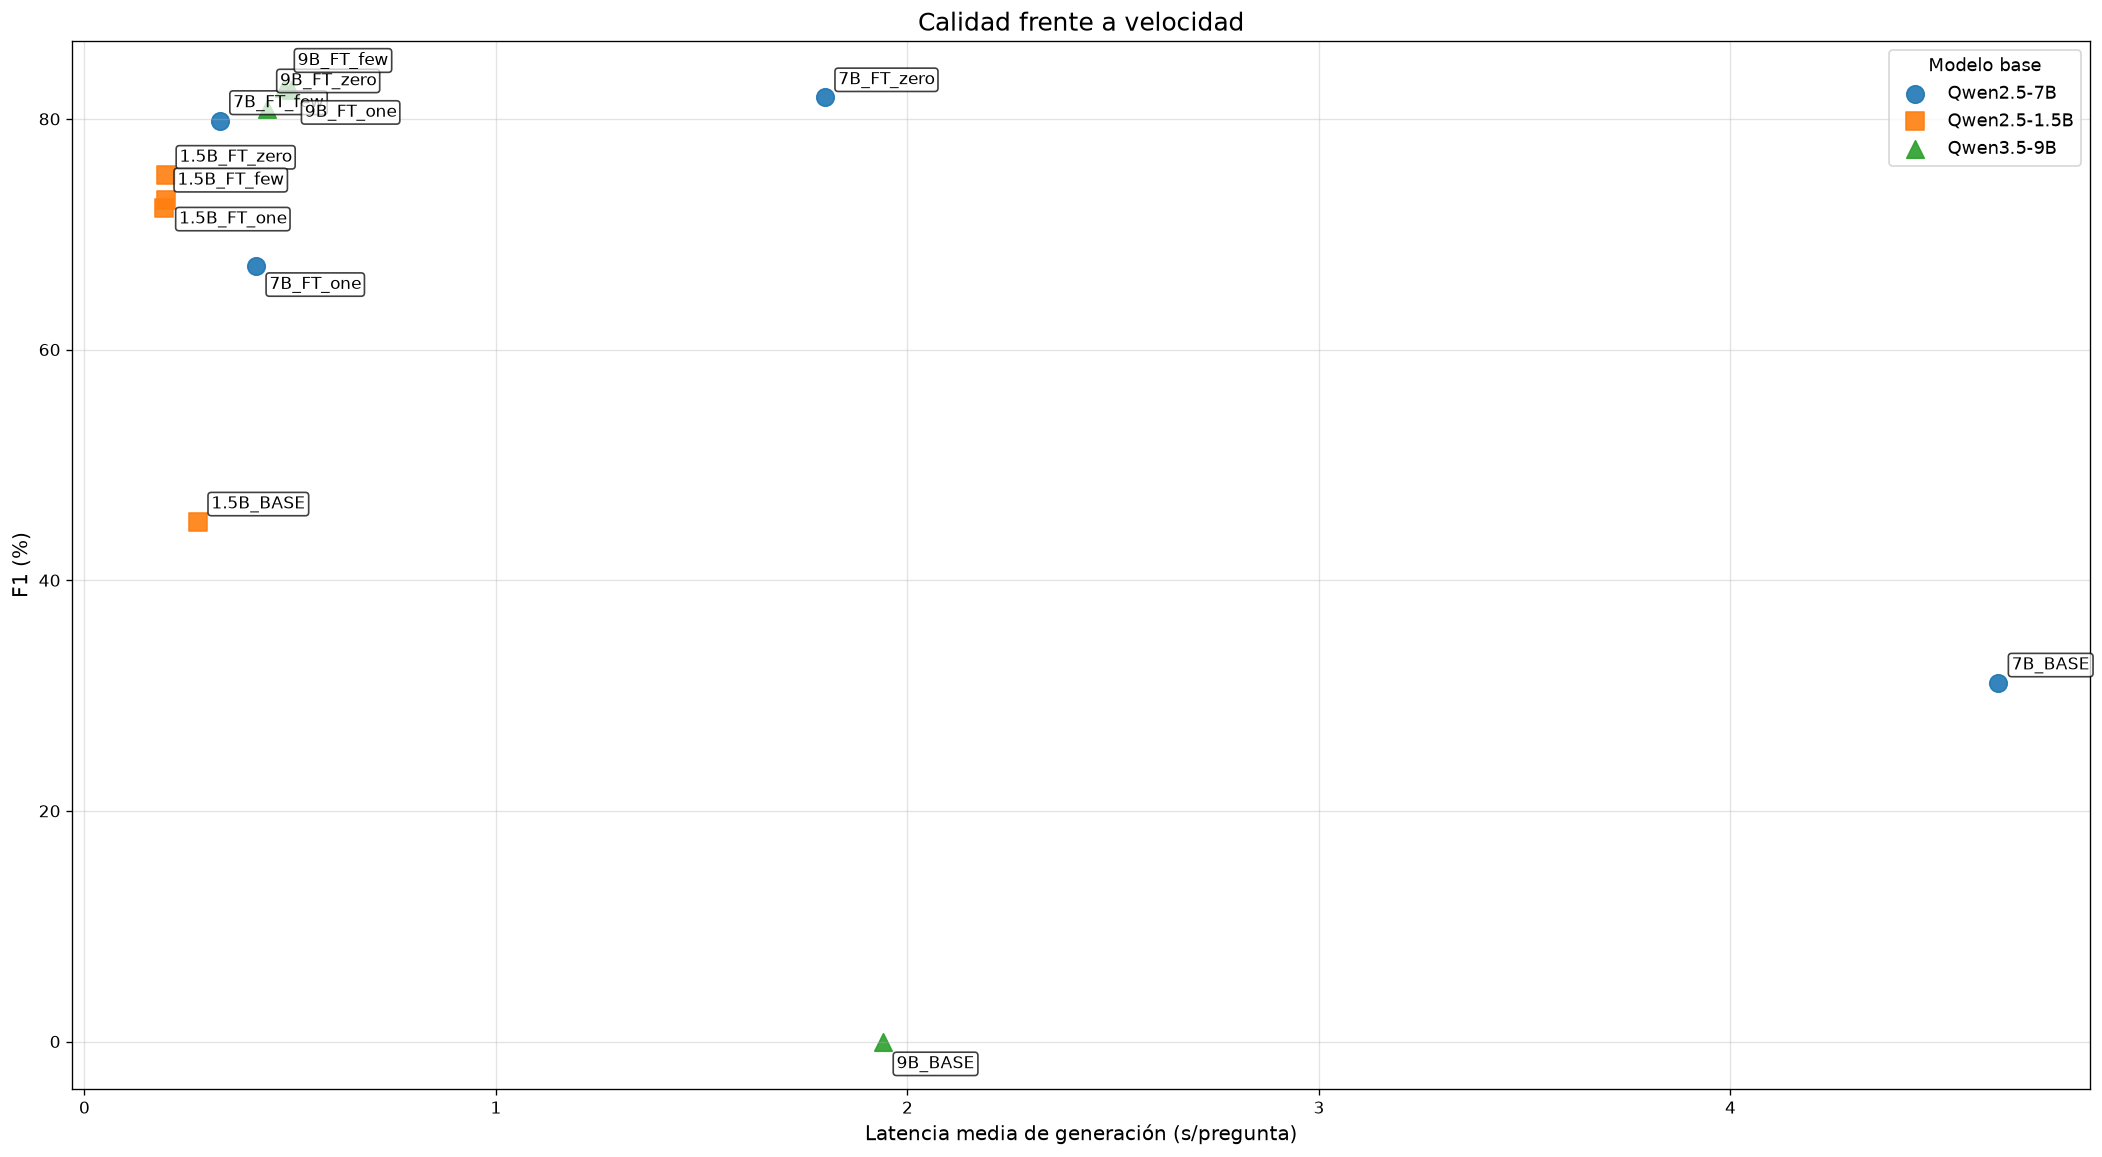

In [21]:
import matplotlib.pyplot as plt

plot_df = summary_df.dropna(
    subset=["F1_percent", "generation_mean_seconds"]
).copy()

if not plot_df.empty:
    plt.figure(figsize=(18, 10), dpi=120)

    label_offsets = {
        "7B_BASE": (8, 8),
        "7B_FT_zero": (8, 8),
        "7B_FT_one": (8, -14),
        "7B_FT_few": (8, 8),
        "1.5B_BASE": (8, 8),
        "1.5B_FT_zero": (8, 8),
        "1.5B_FT_one": (8, -14),
        "1.5B_FT_few": (8, 14),
        "9B_BASE": (8, -16),
        "9B_FT_zero": (8, 14),
        "9B_FT_one": (8, -16),
        "9B_FT_few": (8, 14),
    }

    for family, marker in [("7B", "o"), ("1.5B", "s"), ("9B", "^")]:
        subset = plot_df[plot_df["family"] == family]
        if subset.empty:
            continue

        plt.scatter(
            subset["generation_mean_seconds"],
            subset["F1_percent"],
            marker=marker,
            label={"7B": "Qwen2.5-7B", "1.5B": "Qwen2.5-1.5B", "9B": "Qwen3.5-9B"}[family],
            s=110,
            alpha=0.9,
        )

        for _, row in subset.iterrows():
            dx, dy = label_offsets.get(row["variant"], (8, 8))
            plt.annotate(
                row["variant"],
                (row["generation_mean_seconds"], row["F1_percent"]),
                xytext=(dx, dy),
                textcoords="offset points",
                fontsize=10,
                bbox={"boxstyle": "round,pad=0.2", "fc": "white", "alpha": 0.75},
            )

    plt.xlabel("Latencia media de generación (s/pregunta)", fontsize=12)
    plt.ylabel("F1 (%)", fontsize=12)
    plt.title("Calidad frente a velocidad", fontsize=15)
    plt.grid(True, alpha=0.35)
    plt.legend(title="Modelo base", fontsize=11, title_fontsize=11)
    plt.tight_layout(pad=2.0)
    plt.show()


In [ ]:
# Gr?ficas comparativas incluyendo las variantes Qwen3.5-9B.
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = summary_df[summary_df["variant"].isin([v["name"] for v in VARIANTS])].copy()
plot_df = plot_df.dropna(subset=["F1_percent"])
if not plot_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    sns.barplot(data=plot_df, x="variant", y="F1_percent", hue="family", ax=axes[0], dodge=False)
    axes[0].set_title("F1 por variante")
    axes[0].set_xlabel("Modelo")
    axes[0].set_ylabel("F1 (%)")
    axes[0].tick_params(axis="x", rotation=45)
    axes[0].legend(title="Familia")
    efficiency = plot_df.dropna(subset=["generation_mean_seconds"])
    if not efficiency.empty:
        sns.barplot(data=efficiency, x="variant", y="generation_mean_seconds", hue="family", ax=axes[1], dodge=False)
    axes[1].set_title("Latencia media de generaci?n")
    axes[1].set_xlabel("Modelo")
    axes[1].set_ylabel("Segundos")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].legend(title="Familia")
    plt.tight_layout()
    plt.show()
else:
    print("No hay m?tricas completas para graficar.")
